<a href="https://colab.research.google.com/github/prannav-vg/VLM_fun/blob/main/Video_Anomalies_withReport_VLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Zip: 6.27 GB
Test videos ready: ['Abuse028_x264.mp4', 'Arson009_x264.mp4', 'Arson010_x264.mp4', 'Arson011_x264.mp4', 'Arson018_x264.mp4', 'Assault011_x264.mp4']

=== Abuse028_x264.mp4 | Abuse | 47s ===
   0.0s -   10.0s | ANOMALY | conf 0.90 | a person is seen walking towards a dog
  10.0s -   20.0s | ANOMALY | conf 0.80 | a dog is seen walking on the sidewalk
  20.0s -   30.0s | ANOMALY | conf 0.80 | A man is seen walking up a flight of stairs and then quickly turns around and walks back down the stairs.
  30.0s -   40.0s | ANOMALY | conf 0.80 | A person is seen walking down a set of stairs and then running away from the camera.
  40.0s -   47.1s | ANOMALY | conf 0.80 | A person is seen walking towards the gate from the left side of the frame.

=== Arson009_x264.mp4 | Arson | 25s ===
   0.0s -   10.0s | ANOMALY | conf 0.80 | A person is seen walking towards a van, then suddenly runs away.
  10.0s -   20.0s | ANOMALY | conf 0.80 | A person is seen walking towards a van, then a fire sta

,video,class,length_s,true_anomaly_s,flagged_chunks_s,detected,false_alarm_chunks,video_AUC,model_said
0,Abuse028_x264.mp4,Abuse,47,6-8,"0-10, 10-20, 20-30, 30-40, 40-47",YES,4,0.916,A man is seen walking up a flight of stairs an...
1,Arson009_x264.mp4,Arson,25,7-10,"0-10, 10-20, 20-25",YES,1,0.390,"A person is seen walking towards a van, then a..."
2,Arson010_x264.mp4,Arson,105,30-41,"0-10, 10-20, 20-30, 30-40, 40-50, 50-60, 60-70...",YES,7,0.635,A man in a black jacket and hat is seen walkin...
3,Arson011_x264.mp4,Arson,42,"5-14, 23-42","0-10, 10-20, 20-30, 30-40, 40-42",YES,0,0.714,A man is seen falling backwards into an elevat...
4,Arson018_x264.mp4,Arson,28,9-20,"0-10, 10-20, 20-28",YES,1,0.264,"A car is hit by a vehicle, causing it to crash..."
5,Assault011_x264.mp4,Assault,76,12-32,"0-10, 10-20, 20-30, 30-40, 40-50, 50-60, 60-70...",YES,5,0.500,A man in a blue shirt is walking towards the c...


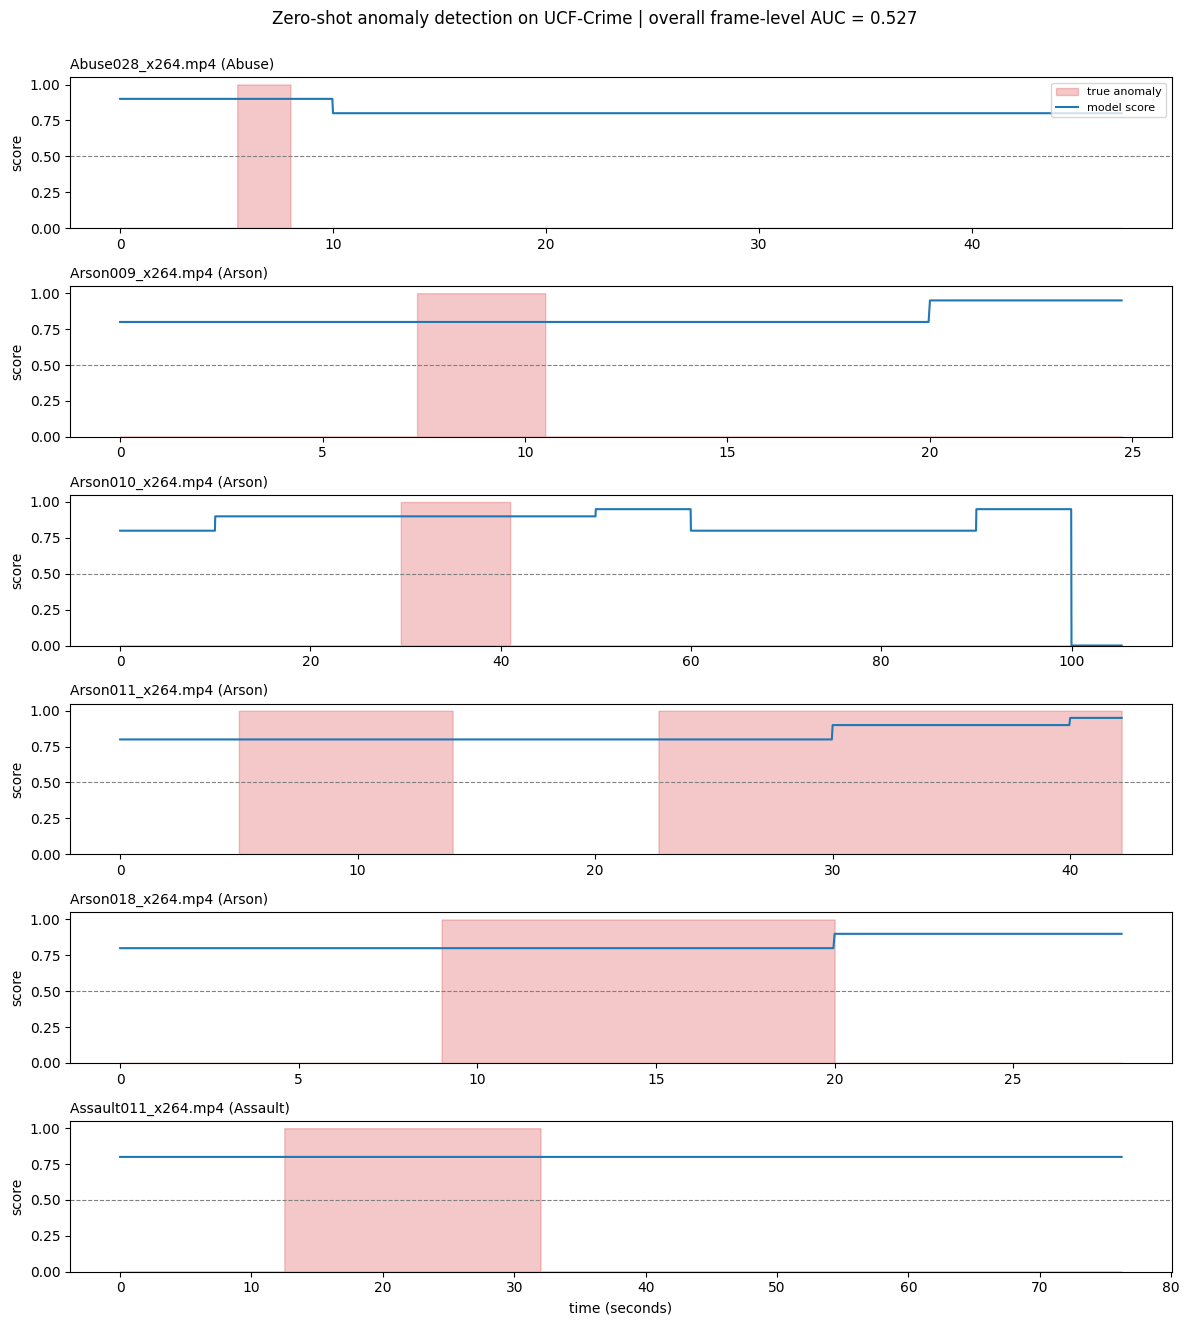

Saved: ucf_results.png, ucf_summary.csv, ucf_chunk_results.csv


In [3]:
!pip -q install -U transformers accelerate qwen-vl-utils av scikit-learn

import os, re, json, zipfile, shutil, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import roc_auc_score
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info

model_id = "Qwen/Qwen2-VL-2B-Instruct"
model = Qwen2VLForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.float16, device_map="auto")
processor = AutoProcessor.from_pretrained(model_id)

LINK = "https://www.dropbox.com/scl/fo/2aczdnx37hxvcfdo4rq4q/ACSm_o3uoOKYRyTX_D4gAlc/Anomaly-Videos-Part-1.zip?rlkey=5bg7mxxbq46t7aujfch46dlvz&dl=1"
ZIP_PATH = "/content/Anomaly-Videos-Part-1.zip"
if not os.path.exists(ZIP_PATH) or os.path.getsize(ZIP_PATH) < 1e9:
    !wget -q --show-progress -O "$ZIP_PATH" "$LINK"
print(f"Zip: {os.path.getsize(ZIP_PATH) / 1e9:.2f} GB")

DATA_DIR = "/content/ucf_test"
os.makedirs(DATA_DIR, exist_ok=True)
ANNOTATION_LINES = """Arson009_x264.mp4  Arson  220  315  -1  -1
Arson010_x264.mp4  Arson  885  1230  -1  -1
Arson011_x264.mp4  Arson  150  420  680  1267
Arson018_x264.mp4  Arson  270  600  -1  -1
Abuse028_x264.mp4  Abuse  165  240  -1  -1
Assault011_x264.mp4  Assault  375  960  -1  -1"""
annotations = {}
for line in ANNOTATION_LINES.splitlines():
    p = line.split()
    s1, e1, s2, e2 = map(int, p[2:6])
    annotations[p[0]] = {"class": p[1], "intervals": [(s, e) for s, e in [(s1, e1), (s2, e2)] if s != -1]}

with zipfile.ZipFile(ZIP_PATH) as z:
    for member in z.namelist():
        base = os.path.basename(member)
        if base in annotations and not os.path.exists(os.path.join(DATA_DIR, base)):
            with z.open(member) as src, open(os.path.join(DATA_DIR, base), "wb") as dst:
                shutil.copyfileobj(src, dst)
videos = sorted(f for f in os.listdir(DATA_DIR) if f in annotations)
print("Test videos ready:", videos)

def ask_video(question, path, fps=1.0):
    messages = [{"role": "user", "content": [
        {"type": "video", "video": path, "max_pixels": 360 * 420, "fps": fps},
        {"type": "text", "text": question}]}]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(text=[text], images=image_inputs, videos=video_inputs,
                       padding=True, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=128)
    out = out[:, inputs.input_ids.shape[1]:]
    return processor.batch_decode(out, skip_special_tokens=True)[0]

ANOMALY_PROMPT = """You are a security video analyst.
Watch this clip carefully. An anomaly is any unusual or dangerous event, for example:
fighting, someone falling, fire or smoke, a vehicle crash, theft, vandalism,
a person collapsing, or people suddenly running in panic.
Normal everyday activity (walking, talking, driving normally) is NOT an anomaly.

Answer ONLY with JSON in this exact format:
{"anomaly": true or false, "confidence": number from 0 to 1, "event": "short description or none"}"""

def parse_answer(text):
    m = re.search(r"\{.*\}", text, re.DOTALL)
    try:
        d = json.loads(m.group(0))
        return {"anomaly": bool(d.get("anomaly", False)), "confidence": float(d.get("confidence", 0.0)),
                "event": str(d.get("event", ""))}
    except Exception:
        return {"anomaly": False, "confidence": 0.0, "event": "unparsed: " + text[:60]}

def video_info(path):
    out = subprocess.run(
        ["ffprobe", "-v", "error", "-select_streams", "v:0", "-count_packets",
         "-show_entries", "stream=r_frame_rate,nb_read_packets", "-of", "csv=p=0", path],
        capture_output=True, text=True, check=True).stdout.strip().split(",")
    num, den = map(int, out[0].split("/"))
    return num / den, int(out[1])

def detect_anomalies(path, duration, chunk_seconds=10, fps=2.0, threshold=0.5):
    results, start = [], 0.0
    while start < duration - 0.5:
        length = min(chunk_seconds, duration - start)
        chunk = f"/content/chunk_{int(start)}.mp4"
        subprocess.run(["ffmpeg", "-y", "-ss", str(start), "-i", path, "-t", str(length),
                        "-c:v", "libx264", "-preset", "veryfast", "-an", chunk],
                       check=True, capture_output=True)
        a = parse_answer(ask_video(ANOMALY_PROMPT, chunk, fps=fps))
        a.update({"start": start, "end": start + length})
        results.append(a)
        flag = "ANOMALY" if a["anomaly"] and a["confidence"] >= threshold else "normal "
        print(f"{start:6.1f}s - {start + length:6.1f}s | {flag} | conf {a['confidence']:.2f} | {a['event']}")
        os.remove(chunk)
        start += chunk_seconds
    return results

CHUNK_SECONDS, THRESHOLD = 10, 0.5
summary_rows, chunk_rows, plot_data, all_truth, all_scores = [], [], [], [], []

for name in videos:
    info = annotations[name]
    path = os.path.join(DATA_DIR, name)
    fps, n_frames = video_info(path)
    duration = n_frames / fps
    print(f"\n=== {name} | {info['class']} | {duration:.0f}s ===")
    results = detect_anomalies(path, duration, CHUNK_SECONDS, threshold=THRESHOLD)

    truth = np.zeros(n_frames)
    for s, e in info["intervals"]:
        truth[max(s, 0):min(e, n_frames)] = 1
    scores = np.zeros(n_frames)
    for r in results:
        s, e = int(r["start"] * fps), min(int(r["end"] * fps), n_frames)
        scores[s:e] = r["confidence"] if r["anomaly"] else 0.0
        chunk_rows.append({"video": name, **r})

    flagged = [r for r in results if r["anomaly"] and r["confidence"] >= THRESHOLD]
    true_secs = [(s / fps, e / fps) for s, e in info["intervals"]]
    overlaps = lambda r: any(r["start"] < te and r["end"] > ts for ts, te in true_secs)
    summary_rows.append({
        "video": name, "class": info["class"], "length_s": round(duration),
        "true_anomaly_s": ", ".join(f"{a:.0f}-{b:.0f}" for a, b in true_secs),
        "flagged_chunks_s": ", ".join(f"{r['start']:.0f}-{r['end']:.0f}" for r in flagged) or "none",
        "detected": "YES" if any(overlaps(r) for r in flagged) else "NO",
        "false_alarm_chunks": sum(1 for r in flagged if not overlaps(r)),
        "video_AUC": round(roc_auc_score(truth, scores), 3) if 0 < truth.sum() < len(truth) else None,
        "model_said": "; ".join(sorted({r["event"] for r in flagged}))[:80] or "-",
    })
    plot_data.append((name, info["class"], fps, truth, scores))
    all_truth.append(truth)
    all_scores.append(scores)

overall_auc = roc_auc_score(np.concatenate(all_truth), np.concatenate(all_scores))
summary = pd.DataFrame(summary_rows)
print("\n" + "=" * 70)
print(f"Model: Qwen2-VL-2B-Instruct (zero-shot) | chunks: {CHUNK_SECONDS}s | threshold: {THRESHOLD}")
print(f"Videos: {len(videos)} UCF-Crime test videos")
print(f"Overall frame-level AUC: {overall_auc:.3f}")
print(f"Anomalies detected: {(summary['detected'] == 'YES').sum()} of {len(videos)} videos")
print(f"Total false-alarm chunks: {summary['false_alarm_chunks'].sum()}")
print("=" * 70)
display(summary)

fig, axes = plt.subplots(len(plot_data), 1, figsize=(12, 2.2 * len(plot_data)), squeeze=False)
for ax, (name, cls, fps, truth, scores) in zip(axes[:, 0], plot_data):
    t = np.arange(len(truth)) / fps
    ax.fill_between(t, 0, truth, color="tab:red", alpha=0.25, step="post", label="true anomaly")
    ax.plot(t, scores, color="tab:blue", lw=1.5, label="model score")
    ax.axhline(THRESHOLD, color="gray", ls="--", lw=0.8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("score")
    ax.set_title(f"{name} ({cls})", fontsize=10, loc="left")
axes[-1, 0].set_xlabel("time (seconds)")
axes[0, 0].legend(loc="upper right", fontsize=8)
plt.suptitle(f"Zero-shot anomaly detection on UCF-Crime | overall frame-level AUC = {overall_auc:.3f}", y=1.0)
plt.tight_layout()
plt.savefig("/content/ucf_results.png", dpi=150, bbox_inches="tight")
plt.show()

summary.to_csv("/content/ucf_summary.csv", index=False)
pd.DataFrame(chunk_rows).to_csv("/content/ucf_chunk_results.csv", index=False)
print("Saved: ucf_results.png, ucf_summary.csv, ucf_chunk_results.csv")